# Temporary instructor study: choose and freeze HTEM chemical features

Students change **models**, not the feature representation. This instructor-only study compares
nine predeclared feature sets with two fixed selectors (Ridge and Random Forest). Every trial
uses the same original grouped training/validation data, observed-label masks and target scaling.
**No test artifact or test score is read during selection.** The previously inspected test set is
not a new untouched confirmation set; this study does not claim universal superiority.

Candidates: existing chemistry with/without DOS, curated Magpie-style descriptors, published
MEGNet composition vectors, real pretrained ALIGNN reference-crystal vectors, and combinations.
Selection: mean relative validation RMSE across the two selectors, normalized by their existing-DOS
baselines, with equal weights. A lower score is better. The selector models are not new workshop
architecture defaults; notebook 02 stays linear Ridge.

### Reading and presenting this notebook

Each code block has a descriptive heading followed by a short explanation labeled **Code Summary:**; saved outputs remain visible. In **VS Code**, open the Command Palette (`Ctrl+Shift+P` on Windows/Linux, `Cmd+Shift+P` on macOS) and choose **Notebook: Collapse All Cell Inputs** (search for `Collapse All Cell Inputs`). Use **Expand All Cell Inputs** to edit, or expand an individual cell using its input control. Do not collapse outputs. VS Code can remember your previous view, so use the command if code is still shown. In **JupyterLab**, code inputs are initially hidden via notebook metadata; expand them with the left-hand cell collapser or the View menu. Hiding code does not disable execution or remove it from the file.


### Configure the instructor chemistry-feature study

Code Summary: Sets up an instructor comparison of candidate chemistry features using fixed Ridge and Random Forest models on grouped training/validation data. Test results are not used to choose features.


In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / '03_htem_conductivity/htem_feature_study.py').exists())
MODULE = ROOT / '03_htem_conductivity'
sys.path.insert(0, str(MODULE))
import htem_feature_study as study
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
display(pd.DataFrame([{'candidate': name, 'added_blocks': ', '.join(blocks) or 'none'}
                      for name, blocks in study.CANDIDATES.items()]))
print('Fixed selectors:', study.ESTIMATORS)

,candidate,added_blocks
0,existing_no_dos,none
1,existing_dos,dos
2,curated,curated
3,curated_composition,"curated, composition"
4,curated_crystal,"curated, crystal"
5,curated_both,"curated, composition, crystal"
6,curated_composition_dos,"curated, composition, dos"
7,curated_crystal_dos,"curated, crystal, dos"
8,curated_both_dos,"curated, composition, crystal, dos"


Fixed selectors: {'ridge': {'alpha': 10.0}, 'forest': {'n_estimators': 200, 'max_depth': 20, 'min_samples_leaf': 3, 'max_features': 0.7, 'random_state': 42, 'n_jobs': 4}}


## Independent references, not measured film information

- **Curated descriptors:** stoichiometry norms, periodic row/column, Mendeleev number, covalent
  radius, elemental melting-temperature statistics and valence-electron statistics/fractions.
  Elemental melting points are not an inferred melting point of the compound or mixture.
- **Composition:** stoichiometric mean of published 16-D formation-energy-trained MEGNet element
  vectors. This is a real pretrained element representation, **not a full Roost/AtomSets model**.
- **Crystal:** official frozen ALIGNN formation-energy checkpoint; mean atom readout before its
  scalar head. Extract from all exact-composition JARVIS reference structures. Fit 16-component PCA
  on **unique active training compositions only**, then transform other references unchanged.
  These are reference phases, not verified HTEM source targets or deposited-film structures.
- **DOS:** existing pinned spin-up reference shape summaries, not film spectra or physical mixture DOS.

Source slots and powers remain paired. No labels, measured film composition, spectra, IDs,
source-gun geometry guesses, or target-specific test information enter any feature.

Instructor extraction (already run for the supplied compact cache):
`scratch/build_htem_feature_candidates.py` in the isolated extraction environment. The workshop
environment does not need ALIGNN/DGL/JARVIS packages. See the module README for reproduction.
References: [MEGNet](https://doi.org/10.1021/acs.chemmater.9b01294),
[ALIGNN](https://doi.org/10.1038/s41524-021-00650-1),
[Magpie](https://doi.org/10.1038/npjcompumats.2016.28).

### Verify reference features and evaluate candidates

Code Summary: Checks reference-crystal provenance and extraction coverage, then evaluates candidate features with training-fitted transformations and validation-based selection.


In [2]:
reference = json.loads(study.REFERENCE.read_text(encoding='utf-8'))
crystals = reference['provenance']['crystal_embedding']
print('Source compositions:', len(reference['compositions']))
print('Real atomic-graph reference extractions:', crystals['reference_structures'])
print('Reported extraction failures:', len(crystals['failures']))
print('Frozen model:', crystals['checkpoint'])
print('Reference/checkpoint archive SHA256:', crystals['archive_sha256'])
results, ranking, decision = study.run_study()

Source compositions: 91
Real atomic-graph reference extractions: 571
Reported extraction failures: 0
Frozen model: jv_formation_energy_peratom_alignn/checkpoint_300.pt
Reference/checkpoint archive SHA256: d80f5e067c0b0b0f569b8158ecfeeeb68472bebe2ceb27ff787dcfcc68948e20


existing_no_dos            ridge   val=0.736062 inputs=136 (0.1s)


existing_no_dos            forest  val=0.658833 inputs=136 (11.0s)


existing_dos               ridge   val=0.753488 inputs=223 (0.1s)


existing_dos               forest  val=0.665827 inputs=223 (19.5s)


curated                    ridge   val=0.729847 inputs=220 (0.1s)


... (9 outputs left out)

curated_crystal_dos        ridge   val=0.722671 inputs=361 (0.1s)


curated_crystal_dos        forest  val=0.658046 inputs=361 (45.9s)


curated_both_dos           ridge   val=0.724650 inputs=412 (0.1s)


curated_both_dos           forest  val=0.663051 inputs=412 (57.6s)


## Validation results and uncertainty

Lower is better. Scores average the two training-standardized log-target RMSEs, so conductivity
does not dominate merely because its numerical units differ. The final selection averages each
selector's score relative to its own existing-DOS baseline. The paired group-bootstrap interval
resamples entire validation recipe groups, not individual grid points. It is descriptive after
selection, not an independent significance test. Feature improvements may differ by architecture.

### Compare validation rankings and exploratory gains

Code Summary: Compares validation errors and relative feature rankings across the two models. The reported exploratory gain interval reflects uncertainty; an interval spanning zero does not establish an improvement.


,candidate,estimator,validation_score,thickness_scaled_RMSE,conductivity_scaled_RMSE,encoded_features,fit_predict_seconds
0,existing_no_dos,ridge,0.73606,0.70141,0.77071,136,0.10491
1,existing_no_dos,forest,0.65883,0.56194,0.75572,136,10.95136
2,existing_dos,ridge,0.75349,0.75373,0.75325,223,0.07599
3,existing_dos,forest,0.66583,0.53649,0.79517,223,19.49335
4,curated,ridge,0.72985,0.71330,0.74640,220,0.06538
5,curated,forest,0.66741,0.57044,0.76438,220,26.18541
6,curated_composition,ridge,0.74530,0.74617,0.74444,271,0.12646
7,curated_composition,forest,0.67332,0.56849,0.77815,271,39.00066
8,curated_crystal,ridge,0.77782,0.76029,0.79535,274,0.07349
9,curated_crystal,forest,0.67474,0.56040,0.78908,274,34.80740


,candidate,mean_relative_validation_score,mean_validation_score,encoded_features
0,curated_crystal_dos,0.97371,0.69036,361
1,curated_both_dos,0.97878,0.69385,412
2,existing_no_dos,0.98318,0.69745,136
3,curated,0.98550,0.69863,220
4,curated_composition_dos,0.98941,0.70114,358
5,existing_dos,1.00000,0.70966,223
6,curated_composition,1.00020,0.70931,271
7,curated_both,1.00702,0.71400,325
8,curated_crystal,1.02284,0.72628,274


Selected: curated_crystal_dos
Exploratory relative-gain interval: [-0.028595573324492883, 0.08290395161952066]


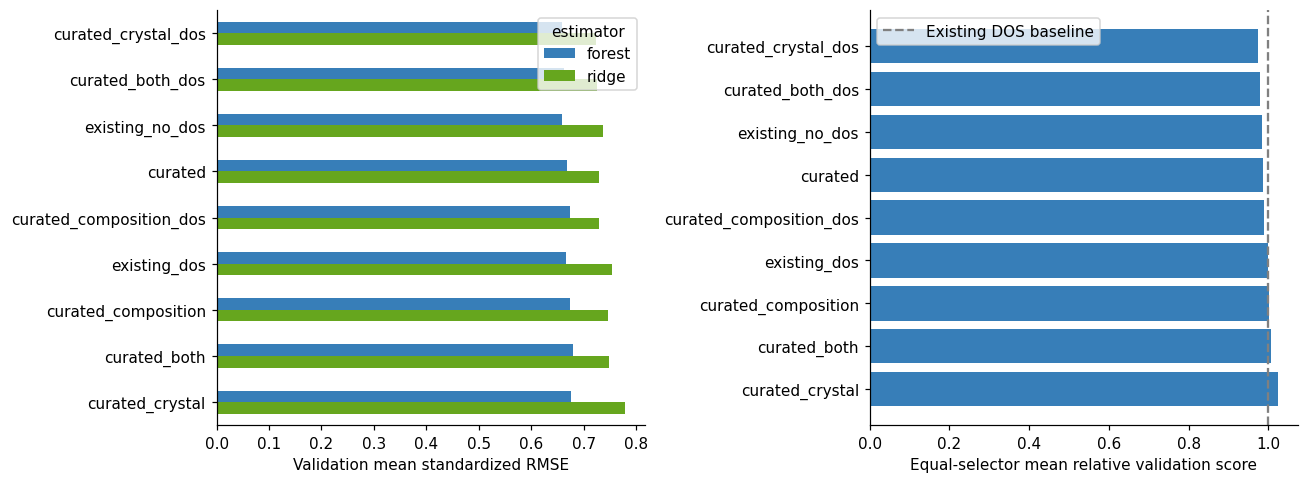

In [3]:
display(results.round(5))
display(ranking.round(5))
print('Selected:', decision['selected_candidate'])
print('Exploratory relative-gain interval:', decision['bootstrap']['relative_gain_interval_95'])
pivot = results.pivot(index='candidate', columns='estimator', values='validation_score').loc[ranking.candidate]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
pivot.plot.barh(ax=axes[0], color=['#377eb8', '#66a61e'])
axes[0].set(xlabel='Validation mean standardized RMSE', ylabel='')
axes[0].invert_yaxis()
axes[1].barh(ranking.candidate, ranking.mean_relative_validation_score, color='#377eb8')
axes[1].axvline(1, color='gray', linestyle='--', label='Existing DOS baseline')
axes[1].set(xlabel='Equal-selector mean relative validation score', ylabel='')
axes[1].invert_yaxis()
axes[1].legend()
fig.tight_layout()
fig.savefig(study.STUDY / 'feature_selection.png', bbox_inches='tight')
plt.show()

## Explicit instructor deployment

Publish the chosen feature specification and compact offline source table. This does **not**
train on validation, change splits, or read the test set. Rerun notebook 01 afterward to create
the shared frozen matrices, followed by all five architecture notebooks and comparison 03.
No architecture may fit its own featurizer. The deployed files retain selection provenance.

### Publish the selected shared feature specification

Code Summary: Publishes the selected feature specification and compact source table for the shared workshop dataset. This instructor step is followed by rerunning preparation, all architectures, and their comparison.


In [4]:
deployed = study.deploy_choice()
print('Published fixed feature specification:', deployed['selected_candidate'])
print('Next: run participant 01, all five 02 architectures, then 03.')

Published fixed feature specification: curated_crystal_dos
Next: run participant 01, all five 02 architectures, then 03.
